# Exploración de biodiversidad ibérica (ES y PT) con la API pública de GBIF

En este cuaderno consultamos la API pública de **GBIF** (*Global Biodiversity Information Facility*) para explorar el catálogo de especies registradas en **España (`ES`) y Portugal (`PT`)**, analizar su denominación científica y común, ver dónde se han observado y descargar, validar y cartografiar registros de presencia de la especie seleccionada (por defecto, *Canis lupus*).

## Objetivo y alcance

El flujo de trabajo se divide en dos fases:

1. **Exploración del catálogo taxonómico en ES y PT:** consulta agregada mediante facetas (`facet=speciesKey`) y metadatos de `/v1/species/{speciesKey}` para listar alfabéticamente las especies presentes en la Península Ibérica, su nombre común en español/portugués y las principales zonas donde se han observado.
2. **Análisis detallado de la especie seleccionada (`ESPECIE_OBJETIVO`):** diagnóstico progresivo de filtros, descarga paginada, normalización Darwin Core, estadísticas territoriales/altitudinales, exportación CSV y mapa interactivo con Folium.

**Filtros aplicados al análisis de ocurrencias:**
- **Taxonomía (`taxonKey`):** resuelto dinámicamente mediante `/v1/species/match`.
- **Países (`country`):** `["ES", "PT"]` (España y Portugal).
- **Periodo (`year`):** `2020,2026` (el año 2026 está incompleto cuando se ejecuta este cuaderno).
- **Calidad espacial:** registros con coordenadas (`hasCoordinate=True`) y sin incidencias geoespaciales (`hasGeospatialIssue=False`).

**Importante:** los recuentos representan registros publicados en GBIF, no la población total ni el número de individuos únicos.

## 0. Preparación del entorno

Se recomienda Python 3.14 y un entorno virtual independiente.

### Opción A: `uv`

```bash
uv venv --python 3.14 .venv

# Windows PowerShell
.venv\\Scripts\\Activate.ps1

# Linux/macOS
# source .venv/bin/activate

uv pip install requests pandas folium matplotlib ipykernel
python -m ipykernel install --user --name=gbif-py314 --display-name="Python 3.14 (GBIF)"
```

### Opción B: `venv` estándar

```bash
python -m venv .venv

# Windows PowerShell
.venv\\Scripts\\Activate.ps1

# Linux/macOS
# source .venv/bin/activate

python -m pip install --upgrade pip
python -m pip install requests pandas folium matplotlib ipykernel
python -m ipykernel install --user --name=gbif-py314 --display-name="Python 3.14 (GBIF)"
```

Selecciona después el kernel **Python 3.14 (GBIF)** en Jupyter o VS Code.

In [1]:
import html
import sys
import time
from typing import Any

import folium
from folium.plugins import MarkerCluster
import matplotlib.pyplot as plt
import pandas as pd
import requests

print(f"Intérprete activo: Python {sys.version.split()[0]}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

# Sesión HTTP reutilizable. El timeout evita esperas indefinidas.
GBIF_API = "https://api.gbif.org/v1"
session = requests.Session()
session.headers.update({
    "User-Agent": "GBIF-Biodiversity-Explorer/2.0 (educational notebook)"
})

Intérprete activo: Python 3.14.3


## 1. Análisis de la API de especies en ES y PT (catálogo alfabético, denominación y zonas)

La API de GBIF permite combinar tres *endpoints* para descubrir qué especies hay registradas en España (`ES`) y Portugal (`PT`) sin necesidad de descargar millones de registros individuales:

- **`/v1/occurrence/search` con `facet=speciesKey`:** devuelve las especies con mayor número de registros (ordenadas por volumen de observaciones) junto con su recuento en `ES` y `PT`.
- **`/v1/species/{speciesKey}` y `/v1/species/{speciesKey}/vernacularNames`:** obtiene la denominación científica oficial del *GBIF Backbone Taxonomy* y los nombres comunes registrados (`spa` / `por`).
- **`/v1/occurrence/search` con `facet=country` y `facet=stateProvince`:** identifica en qué país y provincias/distritos se concentra cada especie.

### Nota sobre el alcance de las facetas y el filtrado taxonómico (`taxon_padre_key`)

En GBIF, `facet=speciesKey` devuelve siempre las `limite_especies` principales ordenadas de mayor a menor número de registros antes de que el cuaderno las ordene **alfabéticamente**. Si se consulta todo el reino `Animalia` (`taxon_padre_key=None`), los primeros puestos están acaparados por aves e insectos con decenas de miles de registros de ciencia ciudadana, por lo que mamíferos como el lobo (*Canis lupus*) quedan fuera del top 25.

Para centrar la exploración en grupos concretos donde aparezcan los mamíferos ibéricos y *Canis lupus*, se utiliza el parámetro **`taxon_padre_key`**:
- `taxon_padre_key=359` → **Mammalia** (mamíferos, opción activada por defecto).
- `taxon_padre_key=9701` → **Canidae** (cánidos: lobo, zorro, etc.).
- `taxon_padre_key=212` → **Aves**.
- `taxon_padre_key=None` → Todo el reino `Animalia`.

El listado resultante se ordena **alfabéticamente por nombre científico** para que puedas elegir cualquier especie y probarla en las celdas siguientes modificando `ESPECIE_OBJETIVO`.

In [2]:
# Configuración global del cuaderno (ámbito ibérico: España y Portugal)
PAISES_OBJETIVO = ["ES", "PT"]
PERIODO_OBJETIVO = "2020,2026"
ESPECIE_OBJETIVO = "Capra pyrenaica"  # <-- Cambia este nombre por cualquiera de la tabla para analizarla
FILTRAR_EXACTAMENTE_ESPECIE_OBJETIVO = True  # <-- Evita que subespecies (ej. Canis familiaris) distorsionen el análisis


def obtener_denominacion_especie(species_key: int) -> dict[str, Any]:
    """Recupera nombre científico, denominación oficial y nombre común (ES/PT)."""
    resp_sp = session.get(f"{GBIF_API}/species/{species_key}", timeout=20)
    resp_sp.raise_for_status()
    info = resp_sp.json()

    nombre_cientifico = info.get("canonicalName") or info.get("scientificName") or f"speciesKey:{species_key}"
    denominacion_oficial = info.get("scientificName", nombre_cientifico)
    reino = info.get("kingdom", "Desconocido")

    resp_vern = session.get(f"{GBIF_API}/species/{species_key}/vernacularNames", timeout=20)
    denominacion_comun = "Sin denominación común registrada"
    if resp_vern.ok:
        resultados_vern = resp_vern.json().get("results", [])
        nombres_es = list(dict.fromkeys(
            v["vernacularName"].strip()
            for v in resultados_vern
            if v.get("language") == "spa" and v.get("vernacularName")
        ))
        nombres_pt = list(dict.fromkeys(
            v["vernacularName"].strip()
            for v in resultados_vern
            if v.get("language") == "por" and v.get("vernacularName")
        ))

        partes = []
        if nombres_es:
            partes.append(f"ES: {', '.join(nombres_es[:2])}")
        if nombres_pt:
            partes.append(f"PT: {', '.join(nombres_pt[:2])}")

        if partes:
            denominacion_comun = " | ".join(partes)
        elif resultados_vern:
            primero = next((v.get("vernacularName") for v in resultados_vern if v.get("vernacularName")), None)
            if primero:
                idioma = resultados_vern[0].get("language", "otro")
                denominacion_comun = f"{primero.strip()} ({idioma})"

    return {
        "speciesKey": species_key,
        "nombre_cientifico": nombre_cientifico,
        "denominacion_oficial": denominacion_oficial,
        "denominacion_comun": denominacion_comun,
        "reino": reino,
    }


def obtener_donde_se_observa(
    species_key: int,
    paises: list[str],
    periodo: str,
    top_territorios: int = 4,
) -> tuple[str, str]:
    """Devuelve el reparto por país (ES vs PT) y las principales provincias/distritos."""
    params = {
        "speciesKey": species_key,
        "country": paises,
        "year": periodo,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
        "limit": 0,
        "facet": ["country", "stateProvince"],
        "facetLimit": top_territorios,
    }
    resp = session.get(f"{GBIF_API}/occurrence/search", params=params, timeout=20)
    if not resp.ok:
        return "No disponible", "No disponible"

    facetas = {f["field"]: f.get("counts", []) for f in resp.json().get("facets", [])}

    reparto_paises = ", ".join(
        f"{c['name']}: {c['count']:,}" for c in facetas.get("COUNTRY", [])
    ) or "Sin datos"

    principales_zonas = ", ".join(
        f"{c['name']} ({c['count']:,})" for c in facetas.get("STATE_PROVINCE", [])
    ) or "Sin territorio especificado"

    return reparto_paises, principales_zonas


def explorar_especies_ibericas(
    paises: list[str] = PAISES_OBJETIVO,
    periodo: str = PERIODO_OBJETIVO,
    reino_key: int | None = 1,
    taxon_padre_key: int | None = None,
    limite_especies: int = 25,
) -> pd.DataFrame:
    """Consulta en GBIF las especies presentes en ES y PT y las ordena alfabéticamente."""
    params: dict[str, Any] = {
        "country": paises,
        "year": periodo,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
        "limit": 0,
        "facet": "speciesKey",
        "facetLimit": limite_especies,
    }
    if reino_key is not None:
        params["kingdomKey"] = reino_key
    if taxon_padre_key is not None:
        params["taxonKey"] = taxon_padre_key

    resp = session.get(f"{GBIF_API}/occurrence/search", params=params, timeout=30)
    resp.raise_for_status()
    payload = resp.json()

    total_ocurrencias = payload.get("count", 0)
    facetas = payload.get("facets", [])
    conteos_especies = facetas[0].get("counts", []) if facetas else []

    print(f"Ámbito consultado: {', '.join(paises)} | Periodo: {periodo}")
    print(f"Total de ocurrencias georreferenciadas que cumplen los filtros: {total_ocurrencias:,}")
    print(f"Especies recuperadas en el top de facetas: {len(conteos_especies)} (ordenando alfabéticamente)...\n")

    filas: list[dict[str, Any]] = []
    for item in conteos_especies:
        sp_key = int(item["name"])
        total_obs = int(item["count"])
        meta = obtener_denominacion_especie(sp_key)
        reparto_pais, zonas = obtener_donde_se_observa(sp_key, paises, periodo)
        meta["observaciones_es_pt"] = total_obs
        meta["reparto_por_pais"] = reparto_pais
        meta["donde_se_observa_top"] = zonas
        filas.append(meta)

    df_esp = pd.DataFrame(filas)
    if not df_esp.empty:
        df_esp = df_esp.sort_values("nombre_cientifico", key=lambda s: s.str.lower()).reset_index(drop=True)
    return df_esp


# Filtramos por la clase Mammalia (taxon_padre_key=359) para que aparezca Canis lupus
# junto con los principales mamíferos ibéricos en ES y PT.
# Alternativas: taxon_padre_key=9701 (familia Canidae) o taxon_padre_key=None (todo Animalia).
df_catalogo_especies = explorar_especies_ibericas(
    paises=PAISES_OBJETIVO,
    periodo=PERIODO_OBJETIVO,
    reino_key=1,
    taxon_padre_key=359,
    limite_especies=25,
)

display(
    df_catalogo_especies[
        [
            "nombre_cientifico",
            "denominacion_comun",
            "denominacion_oficial",
            "observaciones_es_pt",
            "reparto_por_pais",
            "donde_se_observa_top",
        ]
    ]
)

Ámbito consultado: ES, PT | Periodo: 2020,2026
Total de ocurrencias georreferenciadas que cumplen los filtros: 791,918
Especies recuperadas en el top de facetas: 25 (ordenando alfabéticamente)...



,nombre_cientifico,denominacion_comun,denominacion_oficial,observaciones_es_pt,reparto_por_pais,donde_se_observa_top
0,Capra pyrenaica,"ES: Cabra Montesa, Cabra Montés | PT: Cabra do...","Capra pyrenaica Schinz, 1838",26933,"ES: 26,734, PT: 199","Andalucia (7,340), Aragon (5,848), Castilla-La..."
1,Capreolus capreolus,"ES: Corzo, Corzo europeo | PT: Corça, Corço","Capreolus capreolus (Linnaeus, 1758)",97503,"ES: 94,888, PT: 2,615","Castilla y Leon (24,180), Castilla-La Mancha (..."
2,Cervus elaphus,Barbary Red Deer (barbarus) (eng),"Cervus elaphus Linnaeus, 1758",63302,"ES: 62,730, PT: 572","Castilla-La Mancha (13,429), Andalucia (12,180..."
3,Dama dama,ES: Ciervo dama,"Dama dama (Linnaeus, 1758)",17413,"ES: 17,120, PT: 293","Castilla-La Mancha (6,107), Andalucia (4,728),..."
4,Erinaceus europaeus,Adi kirpi (aze),"Erinaceus europaeus Linnaeus, 1758",5142,"ES: 4,025, PT: 1,117","Catalonia (510), Sevilla (309), Asturias (296)..."
5,Felis catus,Agyinamoa (aka),"Felis catus Linnaeus, 1758",8424,"ES: 7,784, PT: 640","Huelva (1,322), Andalucía (1,040), Las Palmas ..."
6,Genetta genetta,PT: Geneta,"Genetta genetta (Linnaeus, 1758)",5141,"ES: 4,747, PT: 394","Catalonia (481), Huelva (340), Barcelona (182)..."
7,Lutra lutra,Adi susamuru (aze),"Lutra lutra (Linnaeus, 1758)",5730,"ES: 5,029, PT: 701","Cáceres (234), Jaén (233), La Rioja (198), Nav..."
8,Martes foina,Akmeninė kiaunė (lit),"Martes foina (Erxleben, 1777)",5671,"ES: 5,339, PT: 332","Catalonia (666), Alicante/Alacant (613), Valen..."
9,Meles meles,Badger (eng),"Meles meles (Linnaeus, 1758)",8323,"ES: 7,733, PT: 590","Catalonia (926), Huelva (301), Burgos (235), N..."


### Selección de la especie para el análisis detallado

La siguiente celda resuelve el `taxonKey` de `ESPECIE_OBJETIVO` (por defecto `Canis lupus`) mediante `/v1/species/match` para ejecutar todo el flujo posterior en **ES y PT**.

In [3]:
def obtener_taxon_key(
    nombre_cientifico: str,
    reino: str = "Animalia",
) -> tuple[int, str]:
    """Resuelve un nombre en GBIF y exige una coincidencia taxonómica exacta."""
    url = f"{GBIF_API}/species/match"
    respuesta = session.get(
        url,
        params={"name": nombre_cientifico, "kingdom": reino, "strict": True},
        timeout=20,
    )
    respuesta.raise_for_status()
    datos: dict[str, Any] = respuesta.json()

    usage_key = datos.get("usageKey")
    nombre_oficial = datos.get("scientificName")
    tipo_coincidencia = datos.get("matchType")

    if usage_key is None or not nombre_oficial:
        raise ValueError(
            f"GBIF no ha encontrado un taxón para {nombre_cientifico!r}. "
            f"Respuesta: {datos}"
        )

    if tipo_coincidencia != "EXACT":
        raise ValueError(
            f"La coincidencia para {nombre_cientifico!r} no es exacta "
            f"(matchType={tipo_coincidencia!r}). Revisa el nombre antes de continuar."
        )

    return int(usage_key), str(nombre_oficial)


taxon_key, nombre_oficial = obtener_taxon_key(ESPECIE_OBJETIVO)
print(f"Taxón activo: {nombre_oficial} -> taxonKey={taxon_key} | Países: {PAISES_OBJETIVO}")

Taxón activo: Capra pyrenaica Schinz, 1838 -> taxonKey=2441054 | Países: ['ES', 'PT']


## 2. Consulta multicriterio en ES y PT con bucle de paginación (`offset` y `limit`)

La API de ocurrencias de GBIF (`/v1/occurrence/search`) admite múltiples valores para el parámetro `country` (en `requests`, pasando una lista como `country=["ES", "PT"]`).

En esta sección ejecutamos primero un diagnóstico progresivo por filtros (incluyendo el desglose individual entre España y Portugal) y descargamos después hasta `MAX_REGISTROS` ocurrencias paginadas de `ESPECIE_OBJETIVO`.

In [4]:
def contar_registros_gbif(parametros: dict[str, Any]) -> int:
    """Consulta el contador de GBIF sin descargar un conjunto de registros."""
    respuesta = session.get(
        f"{GBIF_API}/occurrence/search",
        params={**parametros, "limit": 1, "offset": 0},
        timeout=30,
    )
    respuesta.raise_for_status()
    return int(respuesta.json().get("count", 0))


def descargar_avistamientos_paginados(
    base_params: dict[str, Any],
    max_registros: int = 600,
    tamano_pagina: int = 200,
    pausa_segundos: float = 0.2,
) -> tuple[list[dict[str, Any]], int]:
    """Descarga páginas de occurrence/search y devuelve (registros, total_disponible)."""
    if max_registros < 1:
        raise ValueError("max_registros debe ser mayor que cero.")
    if not 1 <= tamano_pagina <= 300:
        raise ValueError("GBIF admite un limit entre 1 y 300.")
    if pausa_segundos < 0:
        raise ValueError("pausa_segundos no puede ser negativo.")

    url = f"{GBIF_API}/occurrence/search"
    resultados: list[dict[str, Any]] = []
    offset = 0
    total_disponible = 0

    while len(resultados) < max_registros:
        limite = min(tamano_pagina, max_registros - len(resultados))
        parametros = {**base_params, "limit": limite, "offset": offset}

        respuesta = session.get(url, params=parametros, timeout=30)
        respuesta.raise_for_status()
        payload: dict[str, Any] = respuesta.json()

        if offset == 0:
            total_disponible = int(payload.get("count", 0))
            print(f"Total que cumple los filtros en ES + PT según GBIF: {total_disponible:,}")
            print(f"Primera petición: {respuesta.url}")

        lote = payload.get("results", [])
        if not lote:
            break

        resultados.extend(lote)
        print(
            f"Página offset={offset}: +{len(lote)} | "
            f"descargados={len(resultados):,}/{min(total_disponible, max_registros):,}"
        )

        if payload.get("endOfRecords", False):
            print("GBIF indica que se ha alcanzado el final de los resultados.")
            break

        offset += len(lote)
        if pausa_segundos:
            time.sleep(pausa_segundos)

    return resultados, total_disponible


consultas_diagnostico: dict[str, dict[str, Any]] = {
    "1. Solo especie (global)": {
        "taxonKey": taxon_key,
    },
    "2a. Especie + España (ES)": {
        "taxonKey": taxon_key,
        "country": "ES",
    },
    "2b. Especie + Portugal (PT)": {
        "taxonKey": taxon_key,
        "country": "PT",
    },
    "2c. Especie + ES y PT combinados": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
    },
    "3. Especie + ES y PT + periodo 2020-2026": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
    },
    "4. Añadimos coordenadas": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
    },
    "5. Añadimos control geoespacial": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
    },
    "6. Añadimos altitud 1000-3000 (solo diagnóstico)": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
        "elevation": "1000,3000",
    },
}

print(f"=== DIAGNÓSTICO DE FILTROS EN GBIF PARA {ESPECIE_OBJETIVO} ===")
resultados_diagnostico: dict[str, int | None] = {}

for nombre, parametros in consultas_diagnostico.items():
    try:
        total = contar_registros_gbif(parametros)
        resultados_diagnostico[nombre] = total
        print(f"{nombre}: {total:,} registros")
    except requests.RequestException as error:
        resultados_diagnostico[nombre] = None
        print(f"{nombre}: ERROR en la consulta: {error}")

filtros_combinados: dict[str, Any] = {
    "taxonKey": taxon_key,
    "country": PAISES_OBJETIVO,
    "year": PERIODO_OBJETIVO,
    "hasCoordinate": True,
    "hasGeospatialIssue": False,
}

MAX_REGISTROS = 600
registros_crudos, total_disponible_gbif = descargar_avistamientos_paginados(
    filtros_combinados,
    max_registros=MAX_REGISTROS,
    tamano_pagina=200,
)

print(f"\nRegistros descargados: {len(registros_crudos):,}")
print(f"Registros que cumplen los filtros en GBIF: {total_disponible_gbif:,}")
if len(registros_crudos) < total_disponible_gbif:
    print("La descarga está limitada por MAX_REGISTROS; no contiene todos los resultados.")
if total_disponible_gbif == 0:
    print(
        "AVISO: GBIF no devuelve registros con los filtros principales. "
        "Revisa el diagnóstico anterior; no se han relajado los filtros automáticamente."
    )

=== DIAGNÓSTICO DE FILTROS EN GBIF PARA Capra pyrenaica ===
1. Solo especie (global): 99,260 registros
2a. Especie + España (ES): 96,024 registros
2b. Especie + Portugal (PT): 268 registros
2c. Especie + ES y PT combinados: 96,292 registros
3. Especie + ES y PT + periodo 2020-2026: 26,933 registros
4. Añadimos coordenadas: 26,933 registros
5. Añadimos control geoespacial: 26,933 registros
6. Añadimos altitud 1000-3000 (solo diagnóstico): 0 registros
Total que cumple los filtros en ES + PT según GBIF: 26,933
Primera petición: https://api.gbif.org/v1/occurrence/search?taxonKey=2441054&country=ES&country=PT&year=2020%2C2026&hasCoordinate=True&hasGeospatialIssue=False&limit=200&offset=0
Página offset=0: +200 | descargados=200/600
Página offset=200: +200 | descargados=400/600
Página offset=400: +200 | descargados=600/600

Registros descargados: 600
Registros que cumplen los filtros en GBIF: 26,933
La descarga está limitada por MAX_REGISTROS; no contiene todos los resultados.


## 3. Normalización del JSON, prevención taxonómica y limpieza tabular con Pandas

Cada registro devuelto por GBIF sigue el estándar internacional **Darwin Core** y contiene más de 100 atributos (licencias, identificadores de colección, incertidumbre de coordenadas, etc.).

En este paso:
1. Aplanamos la estructura JSON con `pd.json_normalize()`.
2. Seleccionamos las variables clave de espacio, tiempo y procedencia (incluyendo `taxonRank` y `specificEpithet` para auditar subespecies).
3. **Prevención contra contaminación taxonómica (`FILTRAR_EXACTAMENTE_ESPECIE_OBJETIVO`):** en GBIF, consultar por `taxonKey` de una especie padre (como *Canis lupus*, `5219173`) devuelve también registros de subespecies o taxones subordinados (por ejemplo, perro doméstico, *Canis familiaris* / *Canis lupus familiaris*). Filtrar explícitamente por el nombre científico de `ESPECIE_OBJETIVO` garantiza que las estadísticas y mapas reflejen únicamente la especie silvestre deseada.
4. Convertimos las fechas y coordenadas a sus tipos numéricos/temporales adecuados y eliminamos cualquier fila sin coordenadas válidas antes de cartografiar.

In [5]:
columnas_darwin_core = [
    "key", "scientificName", "taxonRank", "specificEpithet", "countryCode",
    "stateProvince", "eventDate", "year", "month", "decimalLatitude",
    "decimalLongitude", "elevation", "basisOfRecord", "institutionCode",
]

df_raw = pd.json_normalize(registros_crudos)
df = df_raw.reindex(columns=columnas_darwin_core).copy()

for columna in ["decimalLatitude", "decimalLongitude", "elevation", "year", "month"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

filas_iniciales = len(df)

# Prevención taxonómica: evita que subespecies (ej. Canis familiaris) distorsionen el análisis
filas_descartadas_taxon = 0
if FILTRAR_EXACTAMENTE_ESPECIE_OBJETIVO and not df.empty:
    mascara_especie = df["scientificName"].str.contains(
        ESPECIE_OBJETIVO, case=False, na=False, regex=False
    )
    descartados_df = df.loc[~mascara_especie]
    filas_descartadas_taxon = len(descartados_df)
    if filas_descartadas_taxon > 0:
        desglose_descartados = descartados_df["scientificName"].fillna("Desconocido").value_counts().to_dict()
        print(
            f"Filtro taxonómico activo: se han excluido {filas_descartadas_taxon:,} registros "
            f"de subespecies/taxones subordinados: {desglose_descartados}"
        )
    df = df.loc[mascara_especie].copy()

filas_tras_taxon = len(df)
mascara_coordenadas = (
    df["decimalLatitude"].between(-90, 90)
    & df["decimalLongitude"].between(-180, 180)
)
df = df.loc[mascara_coordenadas].copy()

df["eventDateParsed"] = pd.to_datetime(df["eventDate"], errors="coerce", utc=True)
df["key"] = df["key"].astype("string")

print(f"Registros recibidos de la API: {filas_iniciales:,}")
print(f"Registros descartados por subespecie/taxón distinto a '{ESPECIE_OBJETIVO}': {filas_descartadas_taxon:,}")
print(f"Registros descartados por coordenadas ausentes o fuera de rango: {filas_tras_taxon - len(df):,}")
print(f"Registros finales válidos para análisis y mapa: {len(df):,}")
print(f"Fechas interpretables por pandas: {df['eventDateParsed'].notna().sum():,}")

if df.empty:
    print("No hay registros válidos para analizar. Revisa los filtros o vuelve a ejecutar la consulta.")
else:
    display(df.head(10))

Registros recibidos de la API: 600
Registros descartados por subespecie/taxón distinto a 'Capra pyrenaica': 0
Registros descartados por coordenadas ausentes o fuera de rango: 0
Registros finales válidos para análisis y mapa: 600
Fechas interpretables por pandas: 203


,key,scientificName,taxonRank,specificEpithet,countryCode,stateProvince,eventDate,year,month,decimalLatitude,decimalLongitude,elevation,basisOfRecord,institutionCode,eventDateParsed
0,5938299262,"Capra pyrenaica hispanica Schimper, 1848",SUBSPECIES,pyrenaica,ES,Andalucía,2026-01-02T13:38,2026,1,36.824530,-2.724340,NaN,HUMAN_OBSERVATION,iNaturalist,2026-01-02 13:38:00+00:00
1,5938498666,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,Cataluña,2026-01-01T15:12:45,2026,1,41.593451,1.837762,NaN,HUMAN_OBSERVATION,iNaturalist,NaT
2,5938525304,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,Andalucía,2026-01-05T16:07:50,2026,1,37.155440,-1.839851,NaN,HUMAN_OBSERVATION,iNaturalist,NaT
3,5938718397,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,Cataluña,2026-01-04T16:44,2026,1,41.594571,1.842813,NaN,HUMAN_OBSERVATION,iNaturalist,2026-01-04 16:44:00+00:00
4,6129675760,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,NaN,2026-01-28T00:00,2026,1,36.707893,-3.395899,NaN,HUMAN_OBSERVATION,NABU|naturgucker,2026-01-28 00:00:00+00:00
5,6129814102,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,Comunidad de Madrid,2026-01-22T13:04:37,2026,1,40.752495,-3.866453,NaN,HUMAN_OBSERVATION,iNaturalist,NaT
6,6129977689,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,Andalucía,2026-01-05T10:21:05,2026,1,36.749297,-5.240775,NaN,HUMAN_OBSERVATION,iNaturalist,NaT
7,6130038201,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,Castilla-La Mancha,2026-01-17T17:08,2026,1,39.199971,-1.428331,NaN,HUMAN_OBSERVATION,iNaturalist,2026-01-17 17:08:00+00:00
8,6130187969,"Capra pyrenaica hispanica Schimper, 1848",SUBSPECIES,pyrenaica,ES,Andalucía,2026-01-10T11:52,2026,1,38.215137,-3.967352,NaN,HUMAN_OBSERVATION,iNaturalist,2026-01-10 11:52:00+00:00
9,6130253383,"Capra pyrenaica Schinz, 1838",SPECIES,pyrenaica,ES,Andalucía,2026-01-07T16:16:52,2026,1,36.600542,-4.638667,NaN,HUMAN_OBSERVATION,iNaturalist,NaT


## 4. Análisis exploratorio y calidad de los datos

Analizamos la distribución territorial, temporal, la altitud y la categoría Darwin Core `basisOfRecord`.

**Precaución de interpretación:** `basisOfRecord` describe la base o naturaleza del registro. No permite deducir automáticamente el método concreto de recogida (por ejemplo, fototrampeo, collar GPS o avistamiento visual). Asimismo, contamos registros, no animales individuales.

In [6]:
if df.empty:
    print("No hay datos válidos. Se omiten las estadísticas.")
else:
    print(f"=== Resumen de la descarga para {nombre_oficial} (ES y PT) ===")
    print(f"Total disponible en GBIF: {total_disponible_gbif:,}")
    print(f"Total descargado de API: {len(registros_crudos):,}")
    print(f"Descartados por filtro taxonómico exacto: {filas_descartadas_taxon:,}")
    print(f"Total final válido (taxón + coordenadas): {len(df):,}")
    print(f"Identificadores de registro únicos: {df['key'].nunique(dropna=True):,}")

    if df["countryCode"].notna().any():
        print("\n=== Distribución por país (ES vs PT) ===")
        display(df["countryCode"].fillna("Sin especificar").value_counts())

    print("\n=== Calidad y campos ausentes ===")
    campos_calidad = [
        "countryCode", "eventDate", "stateProvince", "elevation",
        "basisOfRecord", "institutionCode",
    ]
    resumen_calidad = pd.DataFrame({
        "valores_ausentes": df[campos_calidad].isna().sum(),
        "porcentaje_ausente": (df[campos_calidad].isna().mean() * 100).round(1),
    })
    display(resumen_calidad)

    if df["stateProvince"].notna().any():
        print("\n=== Diez valores territoriales más frecuentes (ES y PT) ===")
        territorio_pais = df["countryCode"].fillna("??") + " - " + df["stateProvince"].fillna("Sin especificar")
        display(territorio_pais.value_counts().head(10))

    if df["basisOfRecord"].notna().any():
        print("\n=== Distribución por basisOfRecord ===")
        display(df["basisOfRecord"].fillna("Sin especificar").value_counts())

    if df["elevation"].notna().any():
        print("\n=== Estadísticas de altitud (metros sobre el nivel del mar) ===")
        display(df["elevation"].describe().round(1))

    if df["year"].notna().any():
        print("\n=== Registros por año ===")
        display(df.groupby("year").size().rename("registros").sort_index())

=== Resumen de la descarga para Capra pyrenaica Schinz, 1838 (ES y PT) ===
Total disponible en GBIF: 26,933
Total descargado de API: 600
Descartados por filtro taxonómico exacto: 0
Total final válido (taxón + coordenadas): 600
Identificadores de registro únicos: 600

=== Distribución por país (ES vs PT) ===


countryCode
ES    561
PT     39
Name: count, dtype: int64


=== Calidad y campos ausentes ===


,valores_ausentes,porcentaje_ausente
countryCode,0,0.0
eventDate,0,0.0
stateProvince,4,0.7
elevation,600,100.0
basisOfRecord,0,0.0
institutionCode,214,35.7



=== Diez valores territoriales más frecuentes (ES y PT) ===


ES - Andalucía              151
ES - Comunidad de Madrid     63
ES - Málaga                  48
ES - Jaén                    42
ES - Cataluña                41
ES - Ávila                   38
PT - Viana do Castelo        36
ES - Castilla y León         25
ES - Granada                 21
ES - Castilla-La Mancha      17
Name: count, dtype: int64


=== Distribución por basisOfRecord ===


basisOfRecord
HUMAN_OBSERVATION    600
Name: count, dtype: int64


=== Registros por año ===


year
2026    600
Name: registros, dtype: int64

## 5. Visualización estadística y exportación de datos

Los gráficos describen los registros descargados y validados; no deben interpretarse como estimaciones directas de abundancia poblacional. Exportamos también el conjunto limpio a CSV para poder reutilizarlo fuera de Jupyter.

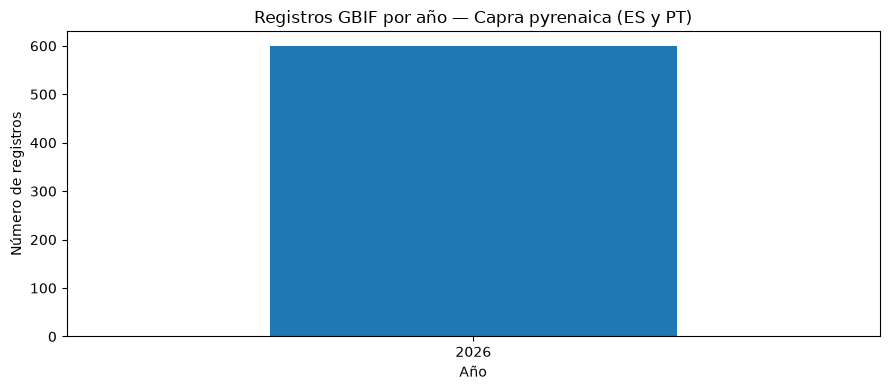

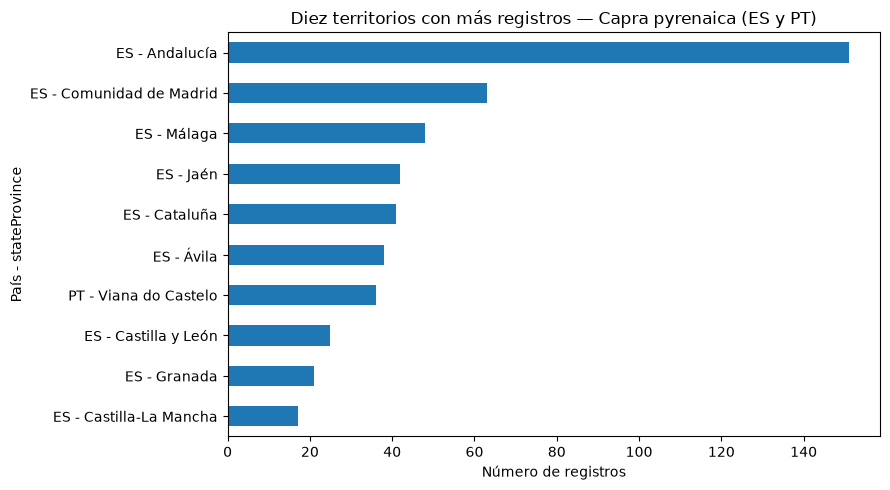

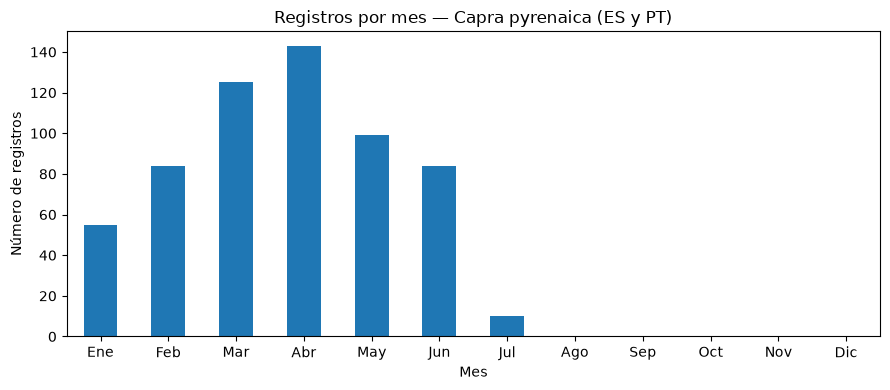

Conjunto limpio exportado a: registros_capra_pyrenaica_es_pt.csv


In [7]:
if not df.empty:
    registros_por_anio = df.dropna(subset=["year"]).groupby("year").size().sort_index()
    if not registros_por_anio.empty:
        ax = registros_por_anio.plot(
            kind="bar", figsize=(9, 4),
            title=f"Registros GBIF por año — {ESPECIE_OBJETIVO} (ES y PT)"
        )
        ax.set_xlabel("Año")
        ax.set_ylabel("Número de registros")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    territorio_pais = df["countryCode"].fillna("??") + " - " + df["stateProvince"].fillna("Sin especificar")
    top_territorios = territorio_pais.value_counts().head(10).sort_values()
    if not top_territorios.empty:
        ax = top_territorios.plot(
            kind="barh", figsize=(9, 5),
            title=f"Diez territorios con más registros — {ESPECIE_OBJETIVO} (ES y PT)"
        )
        ax.set_xlabel("Número de registros")
        ax.set_ylabel("País - stateProvince")
        plt.tight_layout()
        plt.show()

    registros_por_mes = df.dropna(subset=["month"]).groupby("month").size().reindex(range(1, 13), fill_value=0)
    if registros_por_mes.sum() > 0:
        ax = registros_por_mes.plot(
            kind="bar", figsize=(9, 4),
            title=f"Registros por mes — {ESPECIE_OBJETIVO} (ES y PT)"
        )
        ax.set_xlabel("Mes")
        ax.set_ylabel("Número de registros")
        plt.xticks(range(12), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"], rotation=0)
        plt.tight_layout()
        plt.show()

    slug_especie = ESPECIE_OBJETIVO.lower().replace(" ", "_")
    ruta_csv = f"registros_{slug_especie}_es_pt.csv"
    df.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
    print(f"Conjunto limpio exportado a: {ruta_csv}")
else:
    print("No se generan gráficos ni CSV porque no hay registros válidos.")

## 6. Mapa interactivo de registros con Folium

El mapa incorpora agrupación de marcadores (`MarkerCluster`) y dos mapas base:

- **CartoDB Positron:** fondo claro para distinguir los puntos.
- **OpenTopoMap:** relieve topográfico.

Los popups muestran campos disponibles y un enlace a la ficha del registro en GBIF. Los textos procedentes de la API se escapan antes de insertarlos en HTML.

El encuadre se ajusta a la extensión de los puntos mediante `fit_bounds()`. Si no hay datos válidos, se muestra un mapa de referencia de España sin intentar calcular medias de un DataFrame vacío.

In [8]:
if df.empty:
    mapa = folium.Map(location=[40.0, -4.5], zoom_start=6, tiles="CartoDB positron")
    folium.LayerControl().add_to(mapa)
else:
    centro_lat = float(df["decimalLatitude"].median())
    centro_lon = float(df["decimalLongitude"].median())
    mapa = folium.Map(location=[centro_lat, centro_lon], zoom_start=6, tiles="CartoDB positron")

    folium.TileLayer(
        tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
        attr="Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)",
        name="Relieve topográfico (OpenTopoMap)",
        overlay=False,
        control=True,
    ).add_to(mapa)

    cluster = MarkerCluster(name=f"Registros de {ESPECIE_OBJETIVO} (ES y PT)").add_to(mapa)

    for fila in df.itertuples(index=False):
        pais = html.escape(str(fila.countryCode)) if pd.notna(fila.countryCode) else "No especificado"
        fecha = html.escape(str(fila.eventDate)) if pd.notna(fila.eventDate) else "No disponible"
        territorio = html.escape(str(fila.stateProvince)) if pd.notna(fila.stateProvince) else "No especificado"
        altitud = fila.elevation
        altitud_txt = f"{altitud:.0f} m" if pd.notna(altitud) else "No disponible"
        institucion = html.escape(str(fila.institutionCode)) if pd.notna(fila.institutionCode) else "No especificada"
        gbif_id = html.escape(str(fila.key)) if pd.notna(fila.key) else ""
        tipo = html.escape(str(fila.basisOfRecord)) if pd.notna(fila.basisOfRecord) else "No especificado"

        popup_html = f"""
        <div style="font-family: sans-serif; font-size: 13px; min-width: 215px;">
            <b><i>{html.escape(nombre_oficial)}</i></b><hr style="margin: 4px 0;">
            <b>País:</b> {pais}<br>
            <b>Territorio:</b> {territorio}<br>
            <b>Fecha:</b> {fecha}<br>
            <b>Altitud:</b> {altitud_txt}<br>
            <b>Tipo de registro:</b> {tipo}<br>
            <b>Institución:</b> {institucion}<br>
            <a href="https://www.gbif.org/occurrence/{gbif_id}" target="_blank" rel="noopener noreferrer">Ver ficha en GBIF</a>
        </div>
        """

        color_borde = "#1b4332" if pais == "ES" else "#7f1d1d"
        color_relleno = "#2d6a4f" if pais == "ES" else "#b91c1c"

        folium.CircleMarker(
            location=[fila.decimalLatitude, fila.decimalLongitude],
            radius=5,
            color=color_borde,
            fill=True,
            fill_color=color_relleno,
            fill_opacity=0.85,
            popup=folium.Popup(popup_html, max_width=280),
            tooltip=f"[{pais}] {territorio} ({altitud_txt})",
        ).add_to(cluster)

    limites = [
        [float(df["decimalLatitude"].min()), float(df["decimalLongitude"].min())],
        [float(df["decimalLatitude"].max()), float(df["decimalLongitude"].max())],
    ]
    mapa.fit_bounds(limites)
    folium.LayerControl().add_to(mapa)

slug_especie = ESPECIE_OBJETIVO.lower().replace(" ", "_")
ruta_mapa = f"mapa_{slug_especie}_es_pt.html"
mapa.save(ruta_mapa)
print(f"Mapa guardado en: {ruta_mapa}")
mapa

c:\Users\chuwi\Documents\biodiversidad\.venv\Lib\site-packages\folium\raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Mapa guardado en: mapa_capra_pyrenaica_es_pt.html


## 7. Lectura responsable de los resultados y posibles ampliaciones

- El recuento representa **registros** de GBIF, no individuos ni tamaño poblacional.
- `stateProvince` contiene el valor territorial suministrado por la fuente; no siempre equivale a una comunidad autónoma.
- `basisOfRecord` es una categoría Darwin Core, no una descripción completa del método de observación.
- El año 2026 no está completo; evita compararlo directamente con años completos.
- La altitud no se utiliza como filtro de descarga; las estadísticas de elevación se calculan sobre los registros que incluyen ese dato.
- La descarga está limitada por `MAX_REGISTROS`; consulta `total_disponible_gbif` para conocer el total que GBIF indica para esos filtros.

Como ampliaciones, se pueden comparar periodos equivalentes, permitir filtros configurables, añadir capas por año o tipo de registro y estudiar la incertidumbre espacial. Para inferir tendencias poblacionales harían falta datos y métodos específicos, no solo recuentos brutos de ocurrencias.